In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("data/processed/mental_health_cleaned.csv")
RANDOM_STATE = 42


In [ ]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
df.head()


Rows: 10000
Columns: 51


,Age,Gender,Country,Education,Marital_Status,Income_Level,Employment_Status,Work_Hours_Per_Week,Remote_Work,Job_Satisfaction,Work_Stress_Level,Work_Life_Balance,Ever_Bullied_At_Work,Company_Mental_Health_Support,Exercise_Per_Week,Sleep_Hours_Night,Caffeine_Drinks_Day,Alcohol_Frequency,Smoking,Screen_Time_Hours_Day,Social_Media_Hours_Day,Hobby_Time_Hours_Week,Diet_Quality,Financial_Stress,Feeling_Sad_Down,Loss_Of_Interest,Sleep_Trouble,Fatigue,Poor_Appetite_Or_Overeating,Feeling_Worthless,Concentration_Difficulty,Anxious_Nervous,Panic_Attacks,Mood_Swings,Irritability,Obsessive_Thoughts,Compulsive_Behavior,Self_Harm_Thoughts,Suicidal_Thoughts,Family_History_Mental_Illness,Previously_Diagnosed,Ever_Sought_Treatment,On_Therapy_Now,On_Medication,Trauma_History,Social_Support,Close_Friends_Count,Feel_Understood,Loneliness,Discuss_Mental_Health,Has_Mental_Health_Issue
0,40,Male,USA,Some College,Single,Middle,Full-time,27,No,6,7,7,0,No,1-2 times,6.2,3,Never,Former,8.3,4.8,7,Average,9,8,3,10,5,9,4,4,1,0,9,2,3,0,0,0,1,1,1,0,0,0,9,3,4,6,Sometimes,1
1,33,Male,India,Bachelor,Married,Middle,Unemployed,47,No,6,1,5,0,Not sure,1-2 times,9.6,3,Weekly,Current,8.6,0.0,7,Average,9,1,10,4,9,4,10,6,8,2,5,9,9,3,0,0,0,0,0,0,0,0,3,2,7,7,Sometimes,1
2,42,Male,Other,High School,Single,Low,Full-time,53,No,1,3,8,0,Not sure,3-4 times,7.7,1,Never,Former,11.4,3.0,0,Good,2,4,7,8,8,4,9,10,1,0,9,9,7,6,0,0,0,0,1,0,0,1,5,3,6,9,Sometimes,1
3,53,Male,Germany,Bachelor,Single,Middle,Unemployed,42,No,10,3,5,0,No,Never,6.4,1,Rarely,Former,6.4,2.9,5,Average,1,3,8,10,10,2,2,5,3,1,0,2,3,3,0,0,1,0,0,1,0,0,1,3,10,5,Never,1
4,32,Female,India,Bachelor,Single,High,Student,13,No,4,7,7,1,Not sure,1-2 times,7.7,0,Rarely,Current,7.6,4.0,2,Excellent,8,6,8,4,5,4,5,7,10,1,0,10,10,1,0,0,0,1,0,0,0,0,1,5,1,6,Sometimes,1


: 

: 

In [ ]:
target_col = "Has_Mental_Health_Issue"
proxy_drop_cols = [
    "Previously_Diagnosed",
    "Ever_Sought_Treatment",
    "On_Therapy_Now",
    "On_Medication",
]

ordinal_cols = [
    "Education",
    "Income_Level",
    "Exercise_Per_Week",
    "Diet_Quality",
    "Alcohol_Frequency",
    "Discuss_Mental_Health",
]

nominal_cols = [
    "Gender",
    "Country",
    "Marital_Status",
    "Employment_Status",
    "Remote_Work",
    "Company_Mental_Health_Support",
    "Smoking",
]

ordinal_categories = [
    ["High School", "Some College", "Bachelor", "Master", "PhD"],
    ["Low", "Middle", "High"],
    ["Never", "1-2 times", "3-4 times", "5+ times"],
    ["Poor", "Average", "Good", "Excellent"],
    ["Never", "Rarely", "Weekly", "Daily"],
    ["Never", "Rarely", "Sometimes", "Yes easily"],
]

y = df[target_col].astype(int)
X = df.drop(columns=[target_col] + proxy_drop_cols)
numeric_cols = [
    col for col in X.columns
    if col not in ordinal_cols and col not in nominal_cols
]

def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "ordinal",
                OrdinalEncoder(
                    categories=ordinal_categories,
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                ),
                ordinal_cols,
            ),
            (
                "nominal",
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                nominal_cols,
            ),
            ("numeric", "passthrough", numeric_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)


Feature matrix shape: (10000, 46)
Target shape: (10000,)


: 

: 

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train distribution:")
print(y_train.value_counts(normalize=True).round(4))
print("y_test distribution:")
print(y_test.value_counts(normalize=True).round(4))


X_train: (8000, 46)
X_test: (2000, 46)
y_train distribution:
Has_Mental_Health_Issue
1    0.9216
0    0.0784
Name: proportion, dtype: float64
y_test distribution:
Has_Mental_Health_Issue
1    0.9215
0    0.0785
Name: proportion, dtype: float64


: 

: 

In [ ]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
scale_pos_weight


np.float64(0.08504001085040011)

: 

: 

In [ ]:
xgb_baseline = Pipeline(
    steps=[
        ("preprocessor", build_preprocessor()),
        (
            "model",
            XGBClassifier(
                scale_pos_weight=scale_pos_weight,
                random_state=RANDOM_STATE,
                eval_metric="logloss",
            ),
        ),
    ]
)

xgb_baseline.fit(X_train, y_train)
xgb_baseline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tr

: 

: 

In [ ]:
if "xgb_baseline" not in globals():
    xgb_baseline = Pipeline(
        steps=[
            ("preprocessor", build_preprocessor()),
            (
                "model",
                XGBClassifier(
                    scale_pos_weight=scale_pos_weight,
                    random_state=RANDOM_STATE,
                    eval_metric="logloss",
                ),
            ),
        ]
    )
    xgb_baseline.fit(X_train, y_train)

y_pred = xgb_baseline.predict(X_test)
y_proba = xgb_baseline.predict_proba(X_test)[:, 1]

print("F1:", round(f1_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))


F1: 0.9435
Recall: 0.9642
Precision: 0.9236
ROC-AUC: 0.6293


: 

: 

In [ ]:
if "xgb_baseline" not in globals():
    xgb_baseline = Pipeline(
        steps=[
            ("preprocessor", build_preprocessor()),
            (
                "model",
                XGBClassifier(
                    scale_pos_weight=scale_pos_weight,
                    random_state=RANDOM_STATE,
                    eval_metric="logloss",
                ),
            ),
        ]
    )

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = cross_validate(
    xgb_baseline,
    X_train,
    y_train,
    cv=skf,
    scoring=["f1", "precision", "recall", "roc_auc"],
    n_jobs=1,
)

for metric in cv_results:
    if "test" in metric:
        print(metric, round(np.mean(cv_results[metric]), 4), "±", round(np.std(cv_results[metric]), 4))


test_f1 0.9481 ± 0.0018
test_precision 0.9256 ± 0.0014
test_recall 0.9718 ± 0.0033
test_roc_auc 0.605 ± 0.0219


: 

: 

In [ ]:
param_grid = {
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1],
    "model__n_estimators": [100, 200],
}

grid = GridSearchCV(
    estimator=Pipeline(
        steps=[
            ("preprocessor", build_preprocessor()),
            (
                "model",
                XGBClassifier(
                    scale_pos_weight=scale_pos_weight,
                    random_state=RANDOM_STATE,
                    eval_metric="logloss",
                ),
            ),
        ]
    ),
    param_grid=param_grid,
    cv=skf,
    scoring="f1",
    n_jobs=1,
    refit=True,
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_

print("Best CV F1:", round(grid.best_score_, 4))
print("Best parameters:")
print(grid.best_params_)


Best CV F1: 0.9347
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200}


: 

: 

In [ ]:
best_model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tr

: 

: 

In [ ]:
y_pred_final = best_model.predict(X_test)
y_proba_final = best_model.predict_proba(X_test)[:, 1]

print("F1:", round(f1_score(y_test, y_pred_final), 4))
print("Recall:", round(recall_score(y_test, y_pred_final), 4))
print("Precision:", round(precision_score(y_test, y_pred_final), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_final), 4))


NameError: name 'best_model' is not defined

: 

: 

In [ ]:
threshold = 0.35

y_pred_thresh = (y_proba_final >= threshold).astype(int)

print("Recall:", round(recall_score(y_test, y_pred_thresh), 4))
print("Precision:", round(precision_score(y_test, y_pred_thresh), 4))
print("F1:", round(f1_score(y_test, y_pred_thresh), 4))


Recall: 0.9788
Precision: 0.9237
F1: 0.9505


: 

: 

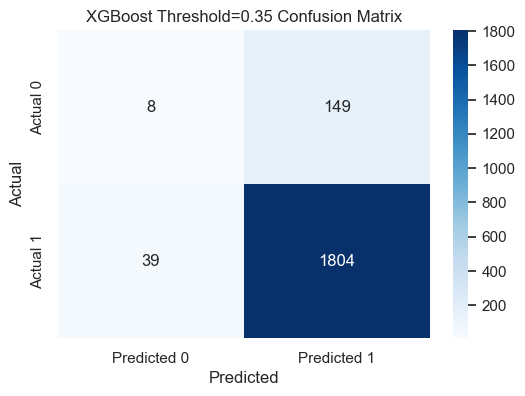

: 

: 

In [ ]:
cm_thresh = confusion_matrix(y_test, y_pred_thresh)
cm_thresh_df = pd.DataFrame(cm_thresh, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"])

plt.figure(figsize=(6, 4))
sns.heatmap(cm_thresh_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"XGBoost Threshold={threshold} Confusion Matrix")
plt.show()


In [ ]:
balanced_acc_default = balanced_accuracy_score(y_test, y_pred_final)
pr_auc_default = average_precision_score(y_test, y_proba_final)

print("Balanced Accuracy:", round(balanced_acc_default, 4))
print("PR-AUC:", round(pr_auc_default, 4))


Balanced Accuracy: 0.5579
PR-AUC: 0.9408


: 

: 

In [ ]:
threshold_summary = pd.DataFrame([
    {
        "threshold": 0.5,
        "precision": round(precision_score(y_test, y_pred_final), 4),
        "recall": round(recall_score(y_test, y_pred_final), 4),
        "f1": round(f1_score(y_test, y_pred_final), 4),
        "balanced_accuracy": round(balanced_accuracy_score(y_test, y_pred_final), 4),
    },
    {
        "threshold": threshold,
        "precision": round(precision_score(y_test, y_pred_thresh), 4),
        "recall": round(recall_score(y_test, y_pred_thresh), 4),
        "f1": round(f1_score(y_test, y_pred_thresh), 4),
        "balanced_accuracy": round(balanced_accuracy_score(y_test, y_pred_thresh), 4),
    },
])

threshold_summary


,threshold,precision,recall,f1,balanced_accuracy
0,0.50,0.9306,0.9311,0.9308,0.5579
1,0.35,0.9237,0.9788,0.9505,0.5149


: 

: 

In [ ]:
print("Precision (class 0):", round(precision_score(y_test, y_pred_final, pos_label=0, zero_division=0), 4))
print("Recall (class 0):", round(recall_score(y_test, y_pred_final, pos_label=0, zero_division=0), 4))
print("F1 (class 0):", round(f1_score(y_test, y_pred_final, pos_label=0, zero_division=0), 4))


Precision (class 0): 0.1859
Recall (class 0): 0.1847
F1 (class 0): 0.1853


: 

: 

In [ ]:
cm_default = confusion_matrix(y_test, y_pred_final)
cm_default_df = pd.DataFrame(cm_default, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"])
cm_default_df


,Predicted 0,Predicted 1
Actual 0,29,128
Actual 1,127,1716


: 

: 

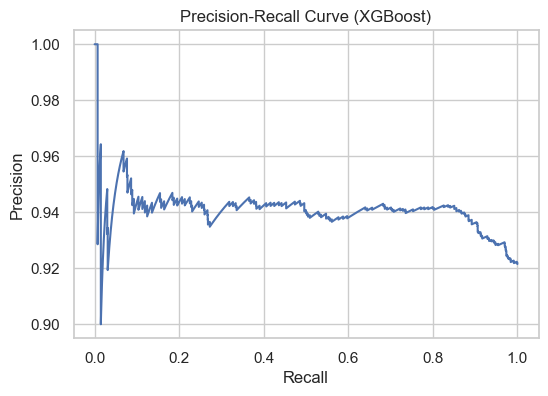

: 

: 

In [ ]:
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_proba_final)

plt.figure(figsize=(6, 4))
plt.plot(rec_curve, prec_curve)
plt.title("Precision-Recall Curve (XGBoost)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()


In [ ]:
proba_1 = y_proba_final
proba_0 = 1 - proba_1
accuracy = accuracy_score(y_test, y_pred_final)
balanced_acc = balanced_accuracy_score(y_test, y_pred_final)

precision_0 = precision_score(y_test, y_pred_final, pos_label=0, zero_division=0)
recall_0 = recall_score(y_test, y_pred_final, pos_label=0, zero_division=0)
f1_0 = f1_score(y_test, y_pred_final, pos_label=0, zero_division=0)

precision_1 = precision_score(y_test, y_pred_final, pos_label=1, zero_division=0)
recall_1 = recall_score(y_test, y_pred_final, pos_label=1, zero_division=0)
f1_1 = f1_score(y_test, y_pred_final, pos_label=1, zero_division=0)

roc_auc_1 = roc_auc_score(y_test, proba_1)
pr_auc_1 = average_precision_score((y_test == 1).astype(int), proba_1)
pr_auc_0 = average_precision_score((y_test == 0).astype(int), proba_0)

print("=== Final Test Evaluation: Tuned XGBoost ===")
print(f"Accuracy               : {accuracy:.4f}")
print(f"Balanced Accuracy      : {balanced_acc:.4f}")

print("\n--- Class 0 (minority) ---")
print(f"Precision_0            : {precision_0:.4f}")
print(f"Recall_0               : {recall_0:.4f}")
print(f"F1_0                   : {f1_0:.4f}")
print(f"PR_AUC_0               : {pr_auc_0:.4f}")

print("\n--- Class 1 (majority) ---")
print(f"Precision_1            : {precision_1:.4f}")
print(f"Recall_1               : {recall_1:.4f}")
print(f"F1_1                   : {f1_1:.4f}")
print(f"PR_AUC_1               : {pr_auc_1:.4f}")
print(f"ROC_AUC_1              : {roc_auc_1:.4f}")

print("\nClassification report:\n")
print(classification_report(y_test, y_pred_final, zero_division=0))

cm = confusion_matrix(y_test, y_pred_final)
cm_df = pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"])
print("\nConfusion matrix:")
print(cm_df)

xgb_comparison_row = pd.DataFrame([
    {
        "Model": "XGBoost",
        "learning_rate": grid.best_params_["model__learning_rate"],
        "max_depth": grid.best_params_["model__max_depth"],
        "max_iter": None,
        "min_samples_leaf": None,
        "n_estimators": grid.best_params_["model__n_estimators"],
        "max_features": None,
        "Selection_Objective": "Best_CV_F1",
        "Selection_Score": round(grid.best_score_, 4),
        "Accuracy": round(accuracy, 4),
        "Balanced_Accuracy": round(balanced_acc, 4),
        "Precision_0": round(precision_0, 4),
        "Recall_0": round(recall_0, 4),
        "F1_0": round(f1_0, 4),
        "PR_AUC_0": round(pr_auc_0, 4),
        "Precision_1": round(precision_1, 4),
        "Recall_1": round(recall_1, 4),
        "F1_1": round(f1_1, 4),
        "PR_AUC_1": round(pr_auc_1, 4),
        "ROC_AUC_1": round(roc_auc_1, 4),
    }
])

xgb_comparison_row.to_csv("data/processed/xgboost_final_row.csv", index=False)
xgb_comparison_row


=== Final Test Evaluation: Tuned XGBoost ===
Accuracy               : 0.8725
Balanced Accuracy      : 0.5579

--- Class 0 (minority) ---
Precision_0            : 0.1859
Recall_0               : 0.1847
F1_0                   : 0.1853
PR_AUC_0               : 0.1435

--- Class 1 (majority) ---
Precision_1            : 0.9306
Recall_1               : 0.9311
F1_1                   : 0.9308
PR_AUC_1               : 0.9408
ROC_AUC_1              : 0.6157

Classification report:

              precision    recall  f1-score   support

           0       0.19      0.18      0.19       157
           1       0.93      0.93      0.93      1843

    accuracy                           0.87      2000
   macro avg       0.56      0.56      0.56      2000
weighted avg       0.87      0.87      0.87      2000


Confusion matrix:
          Predicted 0  Predicted 1
Actual 0           29          128
Actual 1          127         1716


,Model,learning_rate,max_depth,max_iter,min_samples_leaf,n_estimators,max_features,Selection_Objective,Selection_Score,Accuracy,Balanced_Accuracy,Precision_0,Recall_0,F1_0,PR_AUC_0,Precision_1,Recall_1,F1_1,PR_AUC_1,ROC_AUC_1
0,XGBoost,0.1,5,None,None,200,None,Best_CV_F1,0.9347,0.8725,0.5579,0.1859,0.1847,0.1853,0.1435,0.9306,0.9311,0.9308,0.9408,0.6157


: 

: 

: 

: 